# VRDR-Derived Oxia Planum Basemap Project

This notebook is for deriving a set of base-maps for the ExoMars Rosalind Franklin rover Oxia Planum landing site, and it's surrounding region, from the VRDR dataset.

The notebook:
1. Accesses the 4 relevant VRDR tiles (...)
2. Resamples them to the following VNIR instruments:
   1. ESA TGO CaSSIS (4-band)
   2. ESA Mars Express HRSC (5 band?)
   3. NASA MRO HiRISE (3 band)
   4. ESA ExoMars PanCam (12 band)

The goal is to produce floating point I/F resampled cubes, I/F derived spectral parameter cubes, and sets of 3-colour browse products.

In [15]:
# auto reload
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Accessing the VRDR Tiles

I've already prepared a directoy with the required VRDR tiles, so we just need to access that and read the list of files in it.

In [16]:
from pathlib import Path
vrdr_path = Path("/Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr")

In [17]:
quad = "mc11"
tiles = ["t1229", "t1230", "t1301", "t1302"]

In [18]:
import vrdr_resampler as vrdr

In [19]:
mc_path = vrdr_path / quad
lbl_paths = vrdr.get_tile_lbls(mc_path)

In [20]:
lbl_paths

[PosixPath('/Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr/mc11/t1229_vrral_15n333_0654_1.lbl'),
 PosixPath('/Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr/mc11/t1230_vrral_15n338_0654_1.lbl'),
 PosixPath('/Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr/mc11/t1301_vrral_20n333_0654_1.lbl'),
 PosixPath('/Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr/mc11/t1302_vrral_20n338_0654_1.lbl')]

We now have the list of the VRDR cubes.

The way we're going to do this is we'll process 1 VRDR tile at a time, as these have heavy memory loading. Then when we've resampled each tile to a lower number of bands, we'll access those together, and stitch together the mosaics from them.

Let's just read in the first for now.

In [21]:
lbl_path = lbl_paths[0]

In [22]:
vrdr_cube, vrdr_cwls, no_data = vrdr.load_vrdr_tile(lbl_path)

We'll develop and test the resampling on this tile, and then we'll collect the functions and apply them to the other tiles.

# HRSC Resampling

We're not going to produce summary products at this point, just the I/F cubes.

We need to load in the HRSC data.

### Loading the HRSC Spectral Response

Setting a string id for the instrument, that will prefixed to output files:

In [23]:
inst_id = 'x' # we need to distinguish HRSC from HiRISE, we're going to use 'x' for the X in Mars Express, to distinguish from the R in MRO HiRISE.

We'll set a path for the output products.

In [24]:
output_path = vrdr_path.parent / 'vrdr_hrsc'
output_path.mkdir(exist_ok=True) 

out_dir = vrdr.prepare_output_dir(lbl_path, mc_path, output_path, overwrite=True)

Output directory exists, overwriting:  /Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr_hrsc/mc11/t1229_vrral_15n333_0654_1


Setting the path to the instrument file:

In [25]:
# instrument path
inst_path = Path('instrument_response', 'HRSC.csv')

Loading instrument transmission profiles:

In [26]:
hrsc_data = vrdr.load_channel_profiles(inst_path)
band_arr, arr_wvls, band_list, band_cwls = vrdr.unpack_channel_profiles(hrsc_data)

Checking the profile spectral range and resolution:

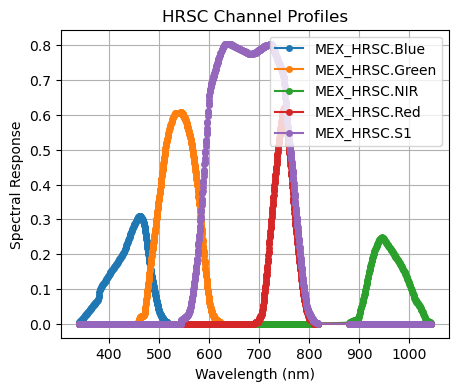

In [27]:
fig, ax = vrdr.plot_channel_profiles(hrsc_data, instrument='HRSC')

In [28]:
xifcub = vrdr.resample_cube(band_arr, arr_wvls, vrdr_cube, vrdr_cwls, no_data)

out_file = vrdr.export_ifcub_geotiff(xifcub, band_list, band_cwls, no_data, inst_id, lbl_path, out_dir)
out_hdr = vrdr.write_ifcub_envi_hdr(band_list, band_cwls, no_data, [4,2,1], inst_id, lbl_path, out_dir)

/opt/homebrew/Caskroom/miniconda/base/envs/vrdr_resampler/lib/python3.14/site-packages/osgeo/gdal.py:606: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


Now we can apply this to the other cubes for HRSC.

In [29]:
for lbl_path in lbl_paths:
    vrdr_cube, vrdr_cwls, no_data = vrdr.load_vrdr_tile(lbl_path)

    xifcub = vrdr.resample_cube(band_arr, arr_wvls, vrdr_cube, vrdr_cwls, no_data)

    out_dir = vrdr.prepare_output_dir(lbl_path, mc_path, output_path, overwrite=True)
    out_file = vrdr.export_ifcub_geotiff(xifcub, band_list, band_cwls, no_data, inst_id, lbl_path, out_dir)
    out_hdr = vrdr.write_ifcub_envi_hdr(band_list, band_cwls, no_data, [4,2,1], inst_id, lbl_path, out_dir)

Output directory exists, overwriting:  /Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr_hrsc/mc11/t1229_vrral_15n333_0654_1
Output directory exists, overwriting:  /Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr_hrsc/mc11/t1230_vrral_15n338_0654_1
Output directory exists, overwriting:  /Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr_hrsc/mc11/t1301_vrral_20n333_0654_1
Output directory exists, overwriting:  /Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr_hrsc/mc11/t1302_vrral_20n338_0654_1


# HiRISE Resampling

In [30]:
inst_id = 'r' # we need to distinguish HRSC from HiRISE, we're going to use 'x' for the X in Mars Express, to distinguish from the R in MRO HiRISE.

We'll set a path for the output products.

In [31]:
output_path = vrdr_path.parent / 'vrdr_hirise'
output_path.mkdir(exist_ok=True) 

Setting the path to the instrument file:

In [32]:
# instrument path
inst_path = Path('instrument_response', 'HiRISE.csv')

Loading instrument transmission profiles:

In [33]:
inst_data = vrdr.load_channel_profiles(inst_path)
band_arr, arr_wvls, band_list, band_cwls = vrdr.unpack_channel_profiles(inst_data)

Checking the profile spectral range and resolution:

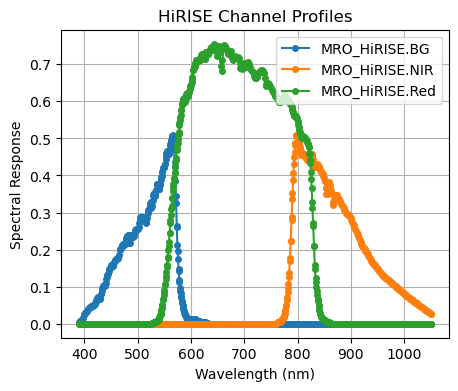

In [34]:
fig, ax = vrdr.plot_channel_profiles(inst_data, instrument='HiRISE')

Now we can apply this to the other cubes for HRSC.

In [35]:
for lbl_path in lbl_paths:
    vrdr_cube, vrdr_cwls, no_data = vrdr.load_vrdr_tile(lbl_path)

    rifcub = vrdr.resample_cube(band_arr, arr_wvls, vrdr_cube, vrdr_cwls, no_data)

    out_dir = vrdr.prepare_output_dir(lbl_path, mc_path, output_path, overwrite=True)
    out_file = vrdr.export_ifcub_geotiff(rifcub, band_list, band_cwls, no_data, inst_id, lbl_path, out_dir)
    out_hdr = vrdr.write_ifcub_envi_hdr(band_list, band_cwls, no_data, [3,2,1], inst_id, lbl_path, out_dir)

Output directory exists, overwriting:  /Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr_hirise/mc11/t1229_vrral_15n333_0654_1
Output directory exists, overwriting:  /Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr_hirise/mc11/t1230_vrral_15n338_0654_1
Output directory exists, overwriting:  /Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr_hirise/mc11/t1301_vrral_20n333_0654_1
Output directory exists, overwriting:  /Volumes/RS_Store/data_archive/oxia_vrdr_base/vrdr_hirise/mc11/t1302_vrral_20n338_0654_1


# PanCam Resampling

In [36]:
inst_id = 'p' # p for PanCam

We'll set a path for the output products.

In [37]:
output_path = vrdr_path.parent / 'vrdr_pancam'
output_path.mkdir(exist_ok=True) 

Setting the path to the instrument file:

In [38]:
# instrument path
inst_path = Path('instrument_response', 'EXMPCGEOL.csv')

Loading instrument transmission profiles:

In [39]:
inst_data = vrdr.load_channel_profiles(inst_path)
band_arr, arr_wvls, band_list, band_cwls = vrdr.unpack_channel_profiles(inst_data)

Checking the profile spectral range and resolution:

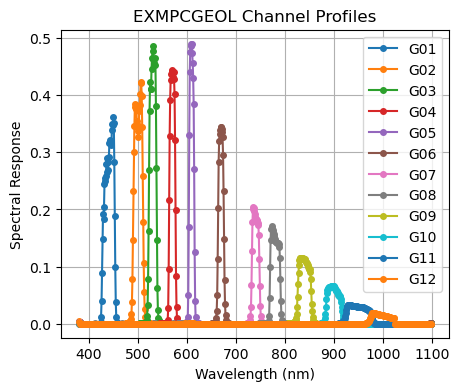

In [40]:
fig, ax = vrdr.plot_channel_profiles(inst_data, instrument='EXMPCGEOL')

Now we can apply this to the other cubes for HRSC.

In [41]:
for lbl_path in lbl_paths:
    vrdr_cube, vrdr_cwls, no_data = vrdr.load_vrdr_tile(lbl_path)

    pifcub = vrdr.resample_cube(band_arr, arr_wvls, vrdr_cube, vrdr_cwls, no_data)

    out_dir = vrdr.prepare_output_dir(lbl_path, mc_path, output_path, overwrite=True)
    out_file = vrdr.export_ifcub_geotiff(pifcub, band_list, band_cwls, no_data, inst_id, lbl_path, out_dir)
    out_hdr = vrdr.write_ifcub_envi_hdr(band_list, band_cwls, no_data, [3,2,1], inst_id, lbl_path, out_dir)